## Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_excel("EastWestAirlines.xlsx", sheet_name="data")
df.head()

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


## Explore the data

In [3]:
print("Shape:", df.shape)
df.info()

Shape: (3999, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ID#                3999 non-null   int64
 1   Balance            3999 non-null   int64
 2   Qual_miles         3999 non-null   int64
 3   cc1_miles          3999 non-null   int64
 4   cc2_miles          3999 non-null   int64
 5   cc3_miles          3999 non-null   int64
 6   Bonus_miles        3999 non-null   int64
 7   Bonus_trans        3999 non-null   int64
 8   Flight_miles_12mo  3999 non-null   int64
 9   Flight_trans_12    3999 non-null   int64
 10  Days_since_enroll  3999 non-null   int64
 11  Award?             3999 non-null   int64
dtypes: int64(12)
memory usage: 375.0 KB


In [4]:
print("Missing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
ID#                  0
Balance              0
Qual_miles           0
cc1_miles            0
cc2_miles            0
cc3_miles            0
Bonus_miles          0
Bonus_trans          0
Flight_miles_12mo    0
Flight_trans_12      0
Days_since_enroll    0
Award?               0
dtype: int64

Duplicate rows: 0


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID#,3999.0,2014.819455,1160.764358,1.0,1010.5,2016.0,3020.5,4021.0
Balance,3999.0,73601.327582,100775.664958,0.0,18527.5,43097.0,92404.0,1704838.0
Qual_miles,3999.0,144.114529,773.663804,0.0,0.0,0.0,0.0,11148.0
cc1_miles,3999.0,2.059515,1.376919,1.0,1.0,1.0,3.0,5.0
cc2_miles,3999.0,1.014504,0.147650,1.0,1.0,1.0,1.0,3.0
cc3_miles,3999.0,1.012253,0.195241,1.0,1.0,1.0,1.0,5.0
Bonus_miles,3999.0,17144.846212,24150.967826,0.0,1250.0,7171.0,23800.5,263685.0
Bonus_trans,3999.0,11.601900,9.603810,0.0,3.0,12.0,17.0,86.0
Flight_miles_12mo,3999.0,460.055764,1400.209171,0.0,0.0,0.0,311.0,30817.0
Flight_trans_12,3999.0,1.373593,3.793172,0.0,0.0,0.0,1.0,53.0


The `ID#` column identifies each customer, so it will not be used as a clustering feature. There are no missing values or duplicate records in the data sheet.

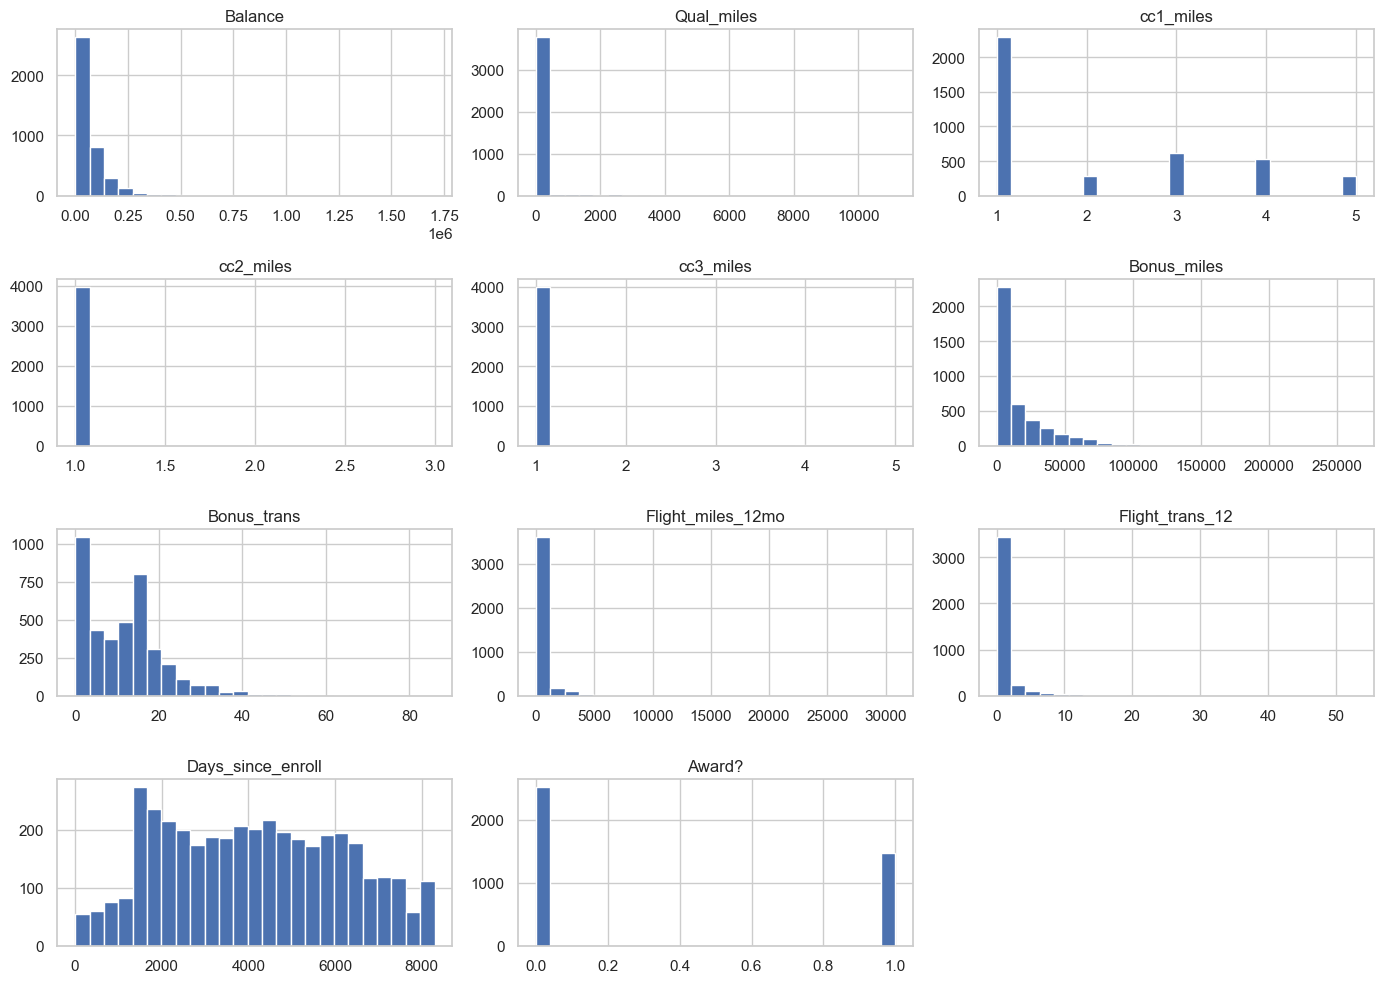

In [6]:
df.drop(columns=["ID#"]).hist(figsize=(14, 10), bins=25)
plt.tight_layout()
plt.show()

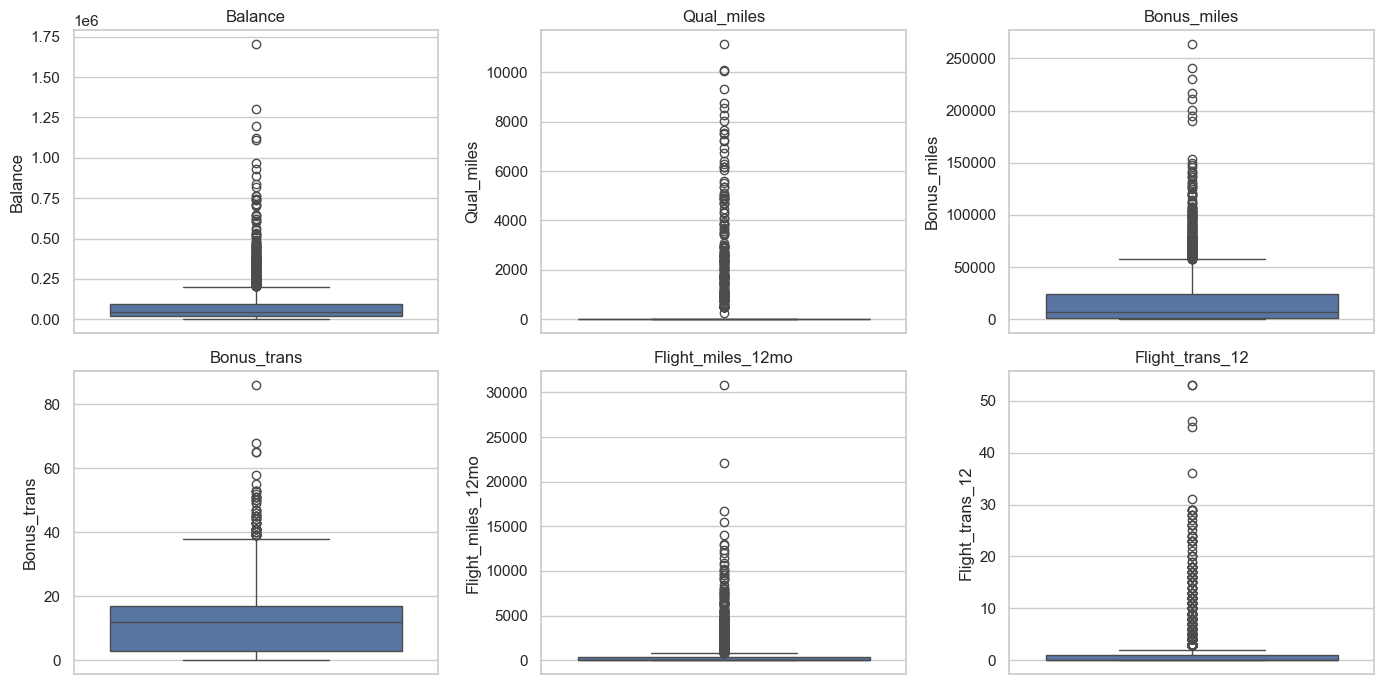

In [7]:
box_cols = ["Balance", "Qual_miles", "Bonus_miles", "Bonus_trans", "Flight_miles_12mo", "Flight_trans_12"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for col, ax in zip(box_cols, axes.flat):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

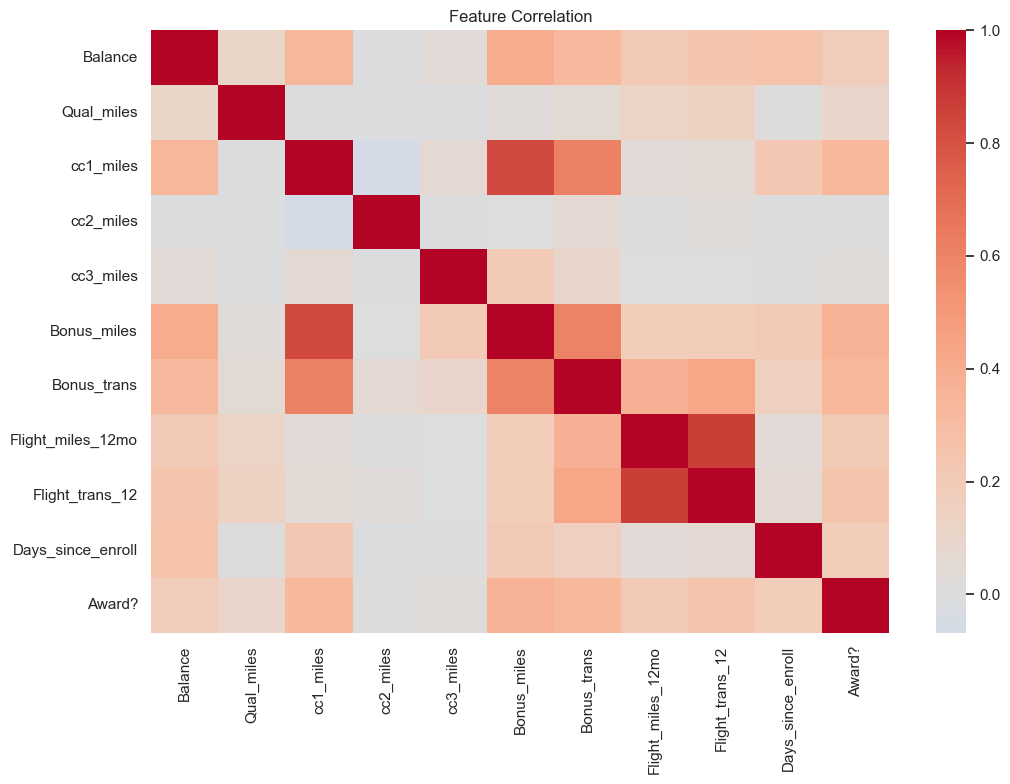

In [8]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.drop(columns=["ID#"]).corr(), cmap="coolwarm", center=0)
plt.title("Feature Correlation")
plt.tight_layout()
plt.show()

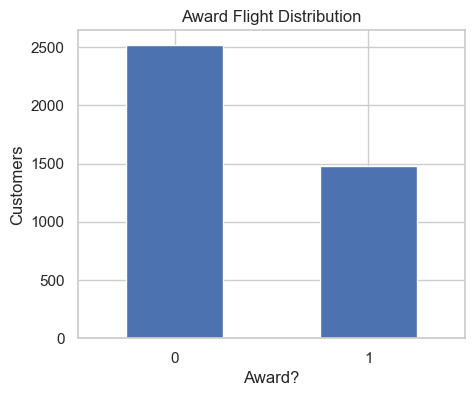

In [9]:
df["Award?"].value_counts().sort_index().plot(kind="bar", figsize=(5, 4))
plt.title("Award Flight Distribution")
plt.xlabel("Award?")
plt.ylabel("Customers")
plt.xticks(rotation=0)
plt.show()

## Prepare the features

In [10]:
features = df.drop(columns=["ID#"]).copy()
continuous_cols = ["Balance", "Qual_miles", "Bonus_miles", "Bonus_trans", "Flight_miles_12mo", "Flight_trans_12", "Days_since_enroll"]

for col in continuous_cols:
    q1 = features[col].quantile(0.25)
    q3 = features[col].quantile(0.75)
    iqr = q3 - q1
    lower = max(0, q1 - 1.5 * iqr)
    upper = q3 + 1.5 * iqr
    features[col] = features[col].clip(lower, upper)

features.head()

,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,28143.0,0,1,1,1,174.0,1,0.0,0.0,7000,0
1,19244.0,0,1,1,1,215.0,2,0.0,0.0,6968,0
2,41354.0,0,1,1,1,4123.0,4,0.0,0.0,7034,0
3,14776.0,0,1,1,1,500.0,1,0.0,0.0,6952,0
4,97752.0,0,4,1,1,43300.0,26,777.5,2.5,6935,1


In [11]:
log_cols = ["Balance", "Qual_miles", "Bonus_miles", "Bonus_trans", "Flight_miles_12mo", "Flight_trans_12"]
features[log_cols] = np.log1p(features[log_cols])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

print("Features used:", features.shape[1])
print("Rows used:", X_scaled.shape[0])

Features used: 11
Rows used: 3999


In [12]:
pd.DataFrame(X_scaled, columns=features.columns).head()

,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,-0.226141,0.0,-0.769578,-0.098242,-0.062767,-0.828232,-1.353766,-0.678186,-0.655276,1.395454,-0.766919
1,-0.536141,0.0,-0.769578,-0.098242,-0.062767,-0.763589,-0.968648,-0.678186,-0.655276,1.379957,-0.766919
2,0.087755,0.0,-0.769578,-0.098242,-0.062767,0.142139,-0.483457,-0.678186,-0.655276,1.411920,-0.766919
3,-0.751609,0.0,-0.769578,-0.098242,-0.062767,-0.505218,-1.353766,-0.678186,-0.655276,1.372208,-0.766919
4,0.789385,0.0,1.409471,-0.098242,-0.062767,0.864239,1.118316,1.621053,1.872364,1.363975,1.303918


## K-Means

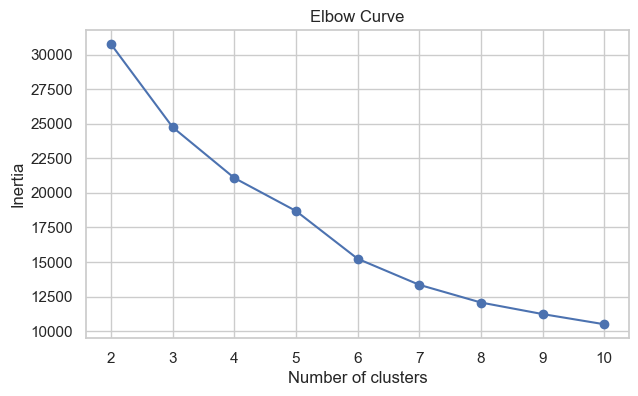

In [13]:
inertia = []
ks = range(2, 11)
for k in ks:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(ks), inertia, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.title("Elbow Curve")
plt.xticks(list(ks))
plt.show()

In [14]:
silhouette_rows = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels, sample_size=2000, random_state=42)
    silhouette_rows.append([k, model.inertia_, score])

kmeans_scores = pd.DataFrame(silhouette_rows, columns=["Clusters", "Inertia", "Silhouette Score"])
kmeans_scores.round(3)

,Clusters,Inertia,Silhouette Score
0,2,30743.753,0.244
1,3,24740.906,0.284
2,4,21074.753,0.292
3,5,18687.709,0.265
4,6,15232.217,0.277
5,7,13348.988,0.283
6,8,12068.349,0.286
7,9,11233.629,0.295
8,10,10497.172,0.290


In [15]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("Cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())
print("Silhouette score:", round(silhouette_score(X_scaled, kmeans_labels), 3))

Cluster sizes:
0    1761
1    1232
2      15
3     991
Name: count, dtype: int64
Silhouette score: 0.288


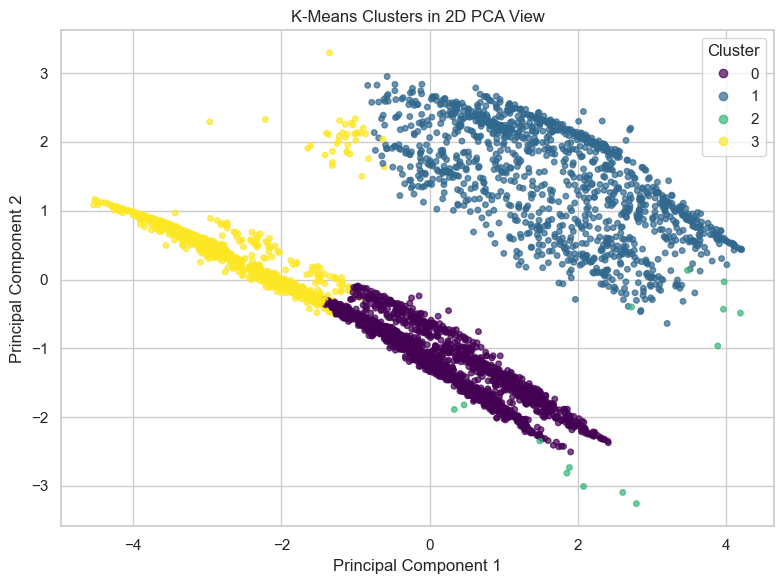

In [16]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap="viridis", s=16, alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters in 2D PCA View")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.tight_layout()
plt.show()

In [17]:
profile = df.copy()
profile["KMeans_Cluster"] = kmeans_labels
kmeans_profile = profile.groupby("KMeans_Cluster").agg(
    Customers=("ID#", "count"),
    Average_Balance=("Balance", "mean"),
    Average_Bonus_Miles=("Bonus_miles", "mean"),
    Average_Flight_Miles_12mo=("Flight_miles_12mo", "mean"),
    Average_Days_Enrolled=("Days_since_enroll", "mean"),
    Award_Rate=("Award?", "mean")
).round(2)
kmeans_profile

,Customers,Average_Balance,Average_Bonus_Miles,Average_Flight_Miles_12mo,Average_Days_Enrolled,Award_Rate
KMeans_Cluster,,,,,,
0,1761,73851.65,20360.77,0.00,4336.82,0.38
1,1232,114062.68,24799.07,1478.59,4424.62,0.59
2,15,138061.40,93927.87,506.67,4613.87,0.53
3,991,21879.73,752.32,10.63,3342.72,0.08


Cluster profiles show the average balance, bonus miles, recent flight activity, enrollment time and award-flight rate in each group. These values can be used to describe the groups as lower-activity, frequent-flyer or reward-focused customers, depending on the profile.

## DBSCAN

In [18]:
dbscan_rows = []
for eps in [1.5, 2.0, 2.5, 3.0]:
    for min_samples in [5, 10]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_mask = labels == -1
        assigned_mask = ~noise_mask
        assigned_labels = labels[assigned_mask]
        if len(set(assigned_labels)) > 1:
            score = silhouette_score(X_scaled[assigned_mask], assigned_labels, sample_size=min(2000, assigned_mask.sum()), random_state=42)
        else:
            score = np.nan
        dbscan_rows.append([eps, min_samples, n_clusters, noise_mask.sum(), noise_mask.mean(), score])

dbscan_tuning = pd.DataFrame(dbscan_rows, columns=["eps", "min_samples", "Clusters", "Noise Points", "Noise Proportion", "Silhouette Score"])
dbscan_tuning.round(3)

,eps,min_samples,Clusters,Noise Points,Noise Proportion,Silhouette Score
0,1.5,5,7,53,0.013,0.182
1,1.5,10,6,62,0.016,0.183
2,2.0,5,5,41,0.010,0.214
3,2.0,10,3,53,0.013,0.205
4,2.5,5,3,24,0.006,0.512
5,2.5,10,2,43,0.011,0.508
6,3.0,5,3,19,0.005,0.511
7,3.0,10,3,19,0.005,0.511


In [19]:
dbscan = DBSCAN(eps=2.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)
non_noise = dbscan_labels != -1
n_db_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)

print("Number of clusters:", n_db_clusters)
print("Noise points:", int((dbscan_labels == -1).sum()))
print("Noise proportion:", round((dbscan_labels == -1).mean(), 3))
if len(set(dbscan_labels[non_noise])) > 1:
    print("Silhouette score (excluding noise):", round(silhouette_score(X_scaled[non_noise], dbscan_labels[non_noise]), 3))

Number of clusters: 3
Noise points: 24
Noise proportion: 0.006
Silhouette score (excluding noise): 0.513


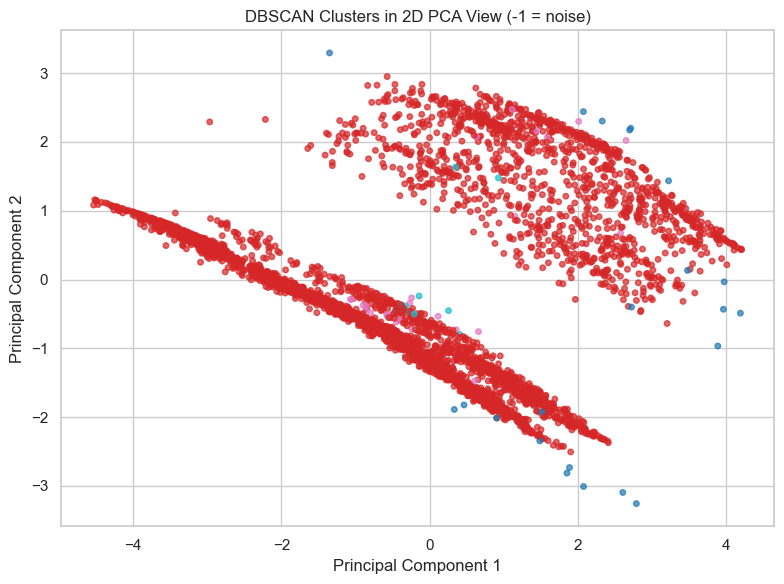

In [20]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap="tab10", s=16, alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Clusters in 2D PCA View (-1 = noise)")
plt.tight_layout()
plt.show()

## Hierarchical clustering

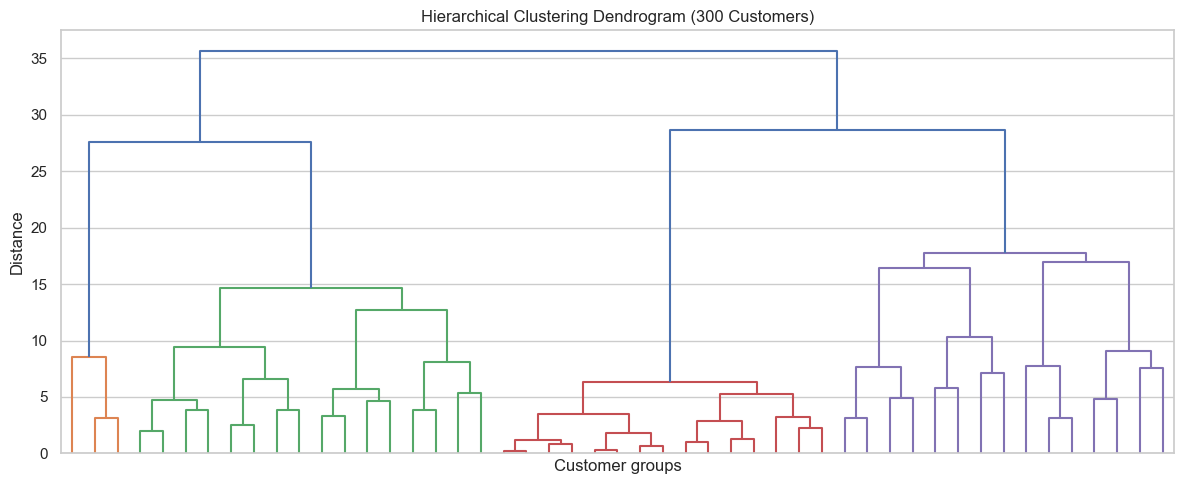

In [21]:
sample_rng = np.random.default_rng(42)
sample_idx = sample_rng.choice(len(X_scaled), size=300, replace=False)
linkage_matrix = linkage(X_scaled[sample_idx], method="ward")

plt.figure(figsize=(12, 5))
dendrogram(linkage_matrix, truncate_mode="level", p=5, no_labels=True)
plt.title("Hierarchical Clustering Dendrogram (300 Customers)")
plt.xlabel("Customer groups")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

In [22]:
hierarchical = AgglomerativeClustering(n_clusters=4, linkage="ward")
hierarchical_labels = hierarchical.fit_predict(X_scaled)

print("Cluster sizes:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())
print("Silhouette score:", round(silhouette_score(X_scaled, hierarchical_labels, sample_size=2000, random_state=42), 3))

Cluster sizes:
0    1268
1    2211
2     477
3      43
Name: count, dtype: int64
Silhouette score: 0.3


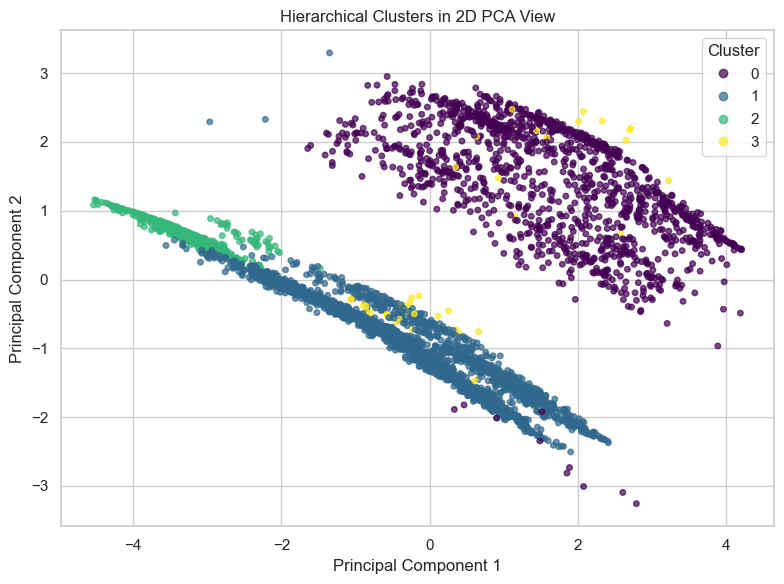

In [23]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=hierarchical_labels, cmap="viridis", s=16, alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Hierarchical Clusters in 2D PCA View")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.tight_layout()
plt.show()

## Compare the algorithms

In [24]:
db_silhouette = np.nan
db_davies = np.nan
if len(set(dbscan_labels[non_noise])) > 1:
    db_silhouette = silhouette_score(X_scaled[non_noise], dbscan_labels[non_noise], sample_size=min(2000, non_noise.sum()), random_state=42)
    db_davies = davies_bouldin_score(X_scaled[non_noise], dbscan_labels[non_noise])

comparison = pd.DataFrame([
    ["K-Means", 4, silhouette_score(X_scaled, kmeans_labels, sample_size=2000, random_state=42), davies_bouldin_score(X_scaled, kmeans_labels), 0],
    ["DBSCAN", n_db_clusters, db_silhouette, db_davies, (dbscan_labels == -1).mean()],
    ["Hierarchical", 4, silhouette_score(X_scaled, hierarchical_labels, sample_size=2000, random_state=42), davies_bouldin_score(X_scaled, hierarchical_labels), 0]
], columns=["Method", "Clusters", "Silhouette Score", "Davies-Bouldin Index", "Noise Proportion"])
comparison.round(3)

,Method,Clusters,Silhouette Score,Davies-Bouldin Index,Noise Proportion
0,K-Means,4,0.292,1.122,0.000
1,DBSCAN,3,0.512,0.653,0.006
2,Hierarchical,4,0.300,1.122,0.000


## Conclusion

K-Means creates a fixed number of customer groups and is useful when the goal is to build simple, interpretable segments. DBSCAN can find dense customer groups and flag unusual records, but it is sensitive to the distance settings and may label some customers as noise. Hierarchical clustering shows how smaller groups can merge into larger groups and is useful for exploring relationships between segments. For this dataset, I would start with K-Means for a straightforward customer segmentation and use DBSCAN as an additional check for dense groups and unusual activity patterns.